In [1]:
from typing import TypedDict

class PortfolioState (TypedDict):
    amount_usd : float
    total_usd : float
    total_inr : float

In [9]:
def calculate_total(state : PortfolioState) -> PortfolioState:
    state['total_usd'] = state['amount_usd'] * 1.08
    return state

def convert_to_inr(state : PortfolioState) -> PortfolioState:
    state['total_inr'] = state['total_usd'] * 85
    return state

In [12]:
from langgraph.graph import StateGraph , START, END

builder = StateGraph(PortfolioState)
builder.add_node("calculate_total_node", calculate_total)
builder.add_node("convert_to_inr_node", convert_to_inr)

builder.add_edge(START, "calculate_total_node")
builder.add_edge("calculate_total_node","convert_to_inr_node")
builder.add_edge("convert_to_inr_node", END)

graph = builder.compile()

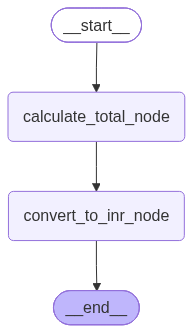

In [13]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [18]:
graph.invoke({'amount_usd':1000})

{'amount_usd': 1000, 'total_usd': 1080.0, 'total_inr': 91800.0}